# 05 - Concept disagreement (RQ2)

Phase P6 of the [implementation plan](../docs/plan/01-rr2-implementation-plan.md).
Same setup as [`04_concept_agreement.ipynb`](04_concept_agreement.ipynb): concept vectors of the 100 members of each
ensemble on the test split, at the `top` (5 concepts) and `leaf` (10 concepts) levels, plus the `protected` view.

**RQ2.** When members disagree on the predicted class, which concepts do they read differently? Is prediction
disagreement correlated with concept disagreement?

Vote margin per sample: `|share voting 1 - share voting 0|` (member vote = `proba > 0.5`); 0 = split vote,
1 = unanimous.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

from project_acl import concepts, ensemble, ontology
from project_acl.preprocess import encode, read, split

sns.set_theme(style="white", context="notebook")
FIG = Path("../docs/figures")
FIG.mkdir(exist_ok=True)

df = read()
X, y, source = encode(df)
X_tr, X_te, y_tr, y_te = split(X, y, df)
X_te, y_te = X_te.to_numpy(float), y_te.to_numpy()
models = ensemble.build(X_tr, y_tr)
proba = {name: ensemble.member_proba(m, X_te) for name, m in models.items()}

# concept vectors v[ensemble, level]: (members, samples, concepts); phi is dropped once aggregated (677 MB each)
LEVELS = {"top": 1, "leaf": 2, "protected": concepts.PROTECTED_VIEW}
labels = {lvl: concepts.column_concepts(X.columns, source, l) for lvl, l in LEVELS.items()}
v, names = {}, {}
for name, m in models.items():
    phi = ensemble.member_contributions(m, X_te)
    for lvl in LEVELS:
        v[name, lvl], names[lvl] = concepts.concept_vectors(phi, labels[lvl])
    del phi
{lvl: names[lvl] for lvl in LEVELS}

[16:18:42] INFO     fitted RF: 100 members                                                           ]8;id=8773096;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=8773097;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

[16:18:48] INFO     fitted LR: 100 members                                                           ]8;id=8773102;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py\ensemble.py]8;;\:]8;id=8773103;file:///home/aprofir/uni/ACL/project/src/project_acl/ensemble.py#41\41]8;;\

{'top': ['Demographics', 'Education', 'Employment', 'Family', 'Finance'],
 'leaf': ['Age',
  'Capital',
  'EducationLevel',
  'HouseholdRole',
  'MaritalStatus',
  'Occupation',
  'Origin',
  'Sector',
  'Sex',
  'WorkTime'],
 'protected': ['Other', 'ProtectedAttribute']}

In [2]:
METRICS = ["top_agreement", "entropy", "kendall"]
margin = {name: concepts.vote_margin(p) for name, p in proba.items()}
agree = pd.concat([
    concepts.agreement(v[name, lvl]).assign(ensemble=name, level=lvl, margin=margin[name])
    for name in models for lvl in ["top", "leaf"]
], ignore_index=True)
BINS, BIN_LABELS = [0, 0.2, 0.5, 0.8, 1, 1.01], ["<0.2", "0.2-0.5", "0.5-0.8", "0.8-1", "1 (unanimous)"]
agree["bucket"] = pd.cut(agree.margin, BINS, labels=BIN_LABELS, right=False)

## 1. Vote-margin buckets

Samples per bucket, and mean concept agreement per bucket.

In [3]:
leaf = agree[agree.level == "leaf"]
print(leaf.groupby(["ensemble", "bucket"], observed=False).size().unstack("bucket"))
agree.groupby(["level", "ensemble", "bucket"], observed=False)[METRICS].mean().unstack("bucket").round(3)

bucket    <0.2  0.2-0.5  0.5-0.8  0.8-1  1 (unanimous)
ensemble                                              
LR         884      947     1675   4546           8229
RF         190      794     1549   3659          10089


top_agreement                                      entropy  \
bucket                  <0.2 0.2-0.5 0.5-0.8  0.8-1 1 (unanimous)    <0.2   
level ensemble                                                              
leaf  LR               0.475   0.475   0.483  0.503         0.524   0.540   
      RF               0.437   0.479   0.584  0.531         0.534   0.601   
top   LR               0.716   0.753   0.738  0.745         0.830   0.447   
      RF               0.506   0.632   0.680  0.800         0.892   0.666   

                                                    kendall                  \
bucket         0.2-0.5 0.5-0.8  0.8-1 1 (unanimous)    <0.2 0.2-0.5 0.5-0.8   
level ensemble                                                                
leaf  LR         0.542   0.537  0.516         0.473   0.355   0.351   0.365   
      RF         0.546   0.473  0.473         0.431   0.334   0.339   0.355   
top   LR         0.427   0.440  0.426         0.320   0.415   0.456   0.467   
      RF         0.542   0.502  0.372         0.217   0.345   0.378   0.397   

                                     
bucket          0.8-1 1 (unanimous)  
level ensemble                       
leaf  LR        0.374         0.379  
      RF        0.346         0.355  
top   LR        0.468         0.501  
      RF        0.418         0.413

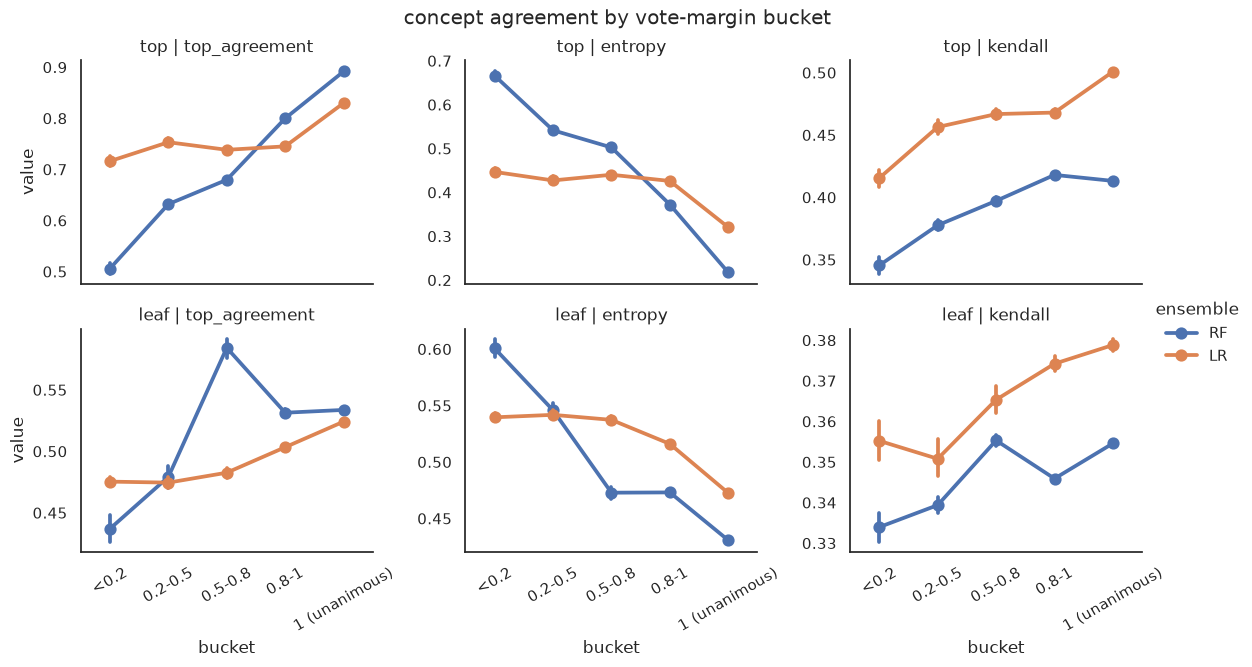

In [4]:
long = agree.melt(id_vars=["ensemble", "level", "bucket"], value_vars=METRICS, var_name="metric")
g = sns.catplot(long, x="bucket", y="value", hue="ensemble", row="level", col="metric", kind="point",
                errorbar=("ci", 95), sharey=False, height=3, aspect=1.3, row_order=["top", "leaf"])
g.set_titles("{row_name} | {col_name}")
g.tick_params(axis="x", rotation=30)
g.figure.suptitle("concept agreement by vote-margin bucket", y=1.02);
plt.gcf().savefig(FIG / "agreement_by_margin.png", dpi=200, bbox_inches="tight")

## 2. Is prediction disagreement correlated with concept disagreement?

Spearman correlation over the test set between the vote margin and each agreement metric (for `entropy`, a positive
link between prediction and concept agreement shows as a negative correlation). The plot shows mean agreement per
margin value (margins are multiples of 0.02).

                top_agreement  entropy  kendall
level ensemble                                 
leaf  LR                0.277   -0.423    0.112
      RF                0.052   -0.315    0.188
top   LR                0.352   -0.389    0.200
      RF                0.594   -0.629    0.080


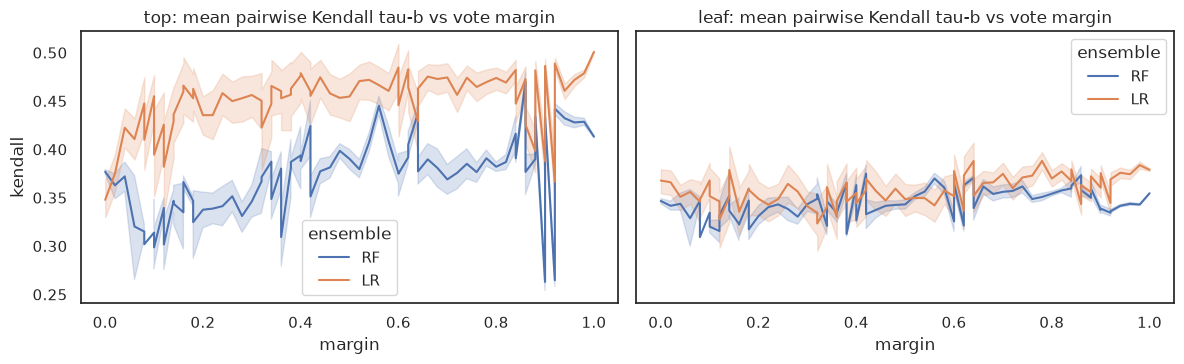

In [5]:
corr = agree.groupby(["level", "ensemble"]).apply(
    lambda d: pd.Series({m: spearmanr(d.margin, d[m]).statistic for m in METRICS}), include_groups=False)
print(corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, lvl in zip(axes, ["top", "leaf"]):
    sns.lineplot(agree[agree.level == lvl], x="margin", y="kendall", hue="ensemble", errorbar=("ci", 95), ax=ax)
    ax.set_title(f"{lvl}: mean pairwise Kendall tau-b vs vote margin")
plt.tight_layout()
plt.gcf().savefig(FIG / "kendall_vs_margin.png", dpi=200, bbox_inches="tight")

Agreement inside each voting camp vs across the whole ensemble, for contested samples (margin < 0.2). If members in
the same camp agree more than the ensemble as a whole, the camps read the sample through different concepts.

In [6]:
rows = []
for name in models:
    low = margin[name] < 0.2
    vote = concepts.votes(proba[name][:, low])
    vl = v[name, "leaf"][:, low]
    whole = concepts.mean_kendall(vl)
    camp = {c: np.array([concepts.mean_kendall(vl[vote[:, i] == c, i : i + 1])[0] for i in range(low.sum())])
            for c in (1, 0)}
    rows.append({"ensemble": name, "samples": int(low.sum()), "whole ensemble": np.nanmean(whole),
                 "camp voting 1": np.nanmean(camp[1]), "camp voting 0": np.nanmean(camp[0])})
pd.DataFrame(rows).set_index("ensemble").round(3)

,samples,whole ensemble,camp voting 1,camp voting 0
ensemble,,,,
RF,190,0.334,0.468,0.329
LR,884,0.355,0.455,0.390


## 3. Which concepts do the two camps read differently?

For contested samples (margin < 0.2): mean concept vector of members voting `>50K` minus that of members voting
`<=50K`, per sample, then averaged. Positive = the `>50K` camp puts more weight on the concept.
`|diff|` is the mean absolute difference (size regardless of direction); `share > 0` is the share of contested
samples in which the `>50K` camp puts more weight on the concept.

diff        |diff|        share > 0       
ensemble                         LR     RF     LR     RF        LR     RF
level     concept                                                        
leaf      Age                -0.003 -0.039  0.016  0.045     0.223  0.389
          Capital             0.146  0.147  0.173  0.162     0.468  0.763
          EducationLevel     -0.012  0.081  0.054  0.164     0.245  0.542
          HouseholdRole      -0.034 -0.054  0.045  0.058     0.200  0.142
          MaritalStatus      -0.054 -0.054  0.072  0.097     0.333  0.447
          Occupation         -0.014  0.029  0.060  0.078     0.310  0.400
          Origin             -0.014 -0.001  0.015  0.001     0.038  0.379
          Sector             -0.006  0.001  0.017  0.006     0.158  0.716
          Sex                -0.016 -0.010  0.018  0.011     0.150  0.032
          WorkTime            0.008 -0.101  0.028  0.101     0.259  0.074
protected Other               0.057  0.064  0.066  0.067     0.869  0.874
          ProtectedAttribute -0.057 -0.064  0.066  0.067     0.131  0.126
top       Demographics       -0.033 -0.050  0.043  0.052     0.153  0.168
          Education          -0.012  0.081  0.054  0.164     0.245  0.542
          Employment         -0.013 -0.071  0.082  0.151     0.364  0.237
          Family             -0.088 -0.108  0.102  0.124     0.250  0.226
          Finance             0.146  0.147  0.173  0.162     0.468  0.763

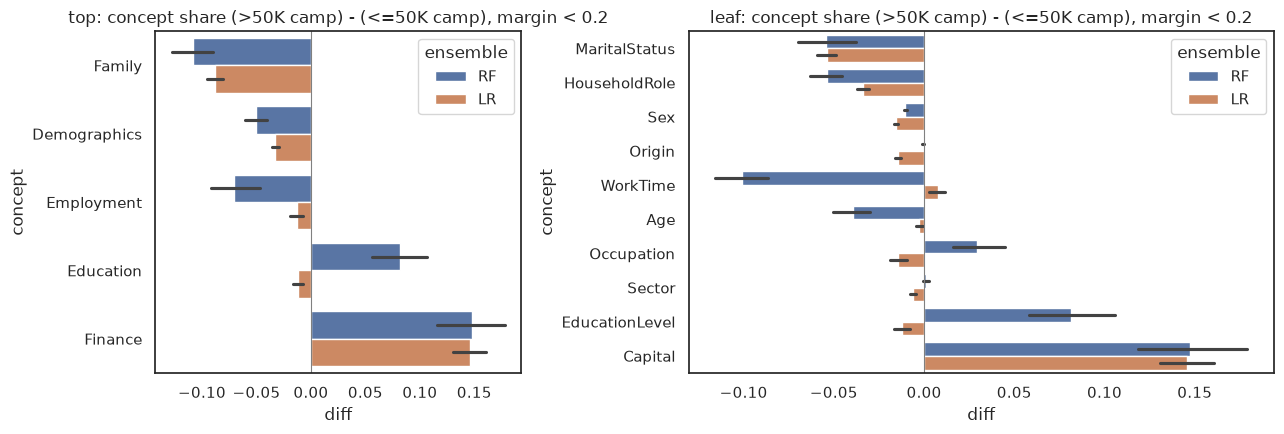

In [7]:
rows = []
for name in models:
    low = margin[name] < 0.2
    for lvl in ["top", "leaf", "protected"]:
        d = concepts.camp_difference(v[name, lvl][:, low], proba[name][:, low])
        rows += [(name, lvl, c, x) for k, c in enumerate(names[lvl]) for x in d[:, k]]
diff = pd.DataFrame(rows, columns=["ensemble", "level", "concept", "diff"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, lvl in zip(axes, ["top", "leaf"]):
    d = diff[diff.level == lvl]
    order = d.groupby("concept")["diff"].mean().sort_values().index
    sns.barplot(d, y="concept", x="diff", hue="ensemble", order=order, errorbar=("ci", 95), ax=ax)
    ax.axvline(0, c="grey", lw=0.8)
    ax.set_title(f"{lvl}: concept share (>50K camp) - (<=50K camp), margin < 0.2")
plt.tight_layout()
plt.gcf().savefig(FIG / "camp_difference.png", dpi=200, bbox_inches="tight")
(diff.assign(abs_diff=diff["diff"].abs(), pos=diff["diff"] > 0)
     .groupby(["level", "concept", "ensemble"])
     .agg(diff=("diff", "mean"), abs_diff=("abs_diff", "mean"), share_pos=("pos", "mean"))
     .unstack("ensemble").round(3)
     .rename(columns={"abs_diff": "|diff|", "share_pos": "share > 0"}))

## 4. Case studies: the most contested test samples

The 4 test samples with the smallest combined vote margin (RF margin + LR margin). For each: the raw features, the
true label, each ensemble's vote share for `>50K`, and the mean leaf concept vector of each voting camp.

In [8]:
test_df = df[df["split"] == "test"].reset_index(drop=True)
cases = np.argsort(margin["RF"] + margin["LR"], kind="stable")[:4]
info = test_df.loc[cases].drop(columns=["split", "fnlwgt"]).copy()
for name in models:
    info[f"{name} vote >50K"] = concepts.votes(proba[name][:, cases]).mean(axis=0)
info.T

,13037,13211,7090,13135
age,60,68,46,62
workclass,Self-emp-inc,Self-emp-not-inc,Private,NaN
education,10th,Masters,HS-grad,Masters
education-num,6,14,9,14
marital-status,Married-civ-spouse,Married-civ-spouse,Married-civ-spouse,Married-civ-spouse
occupation,Exec-managerial,Transport-moving,Craft-repair,NaN
relationship,Husband,Husband,Wife,Husband
race,White,White,White,White
sex,Male,Male,Female,Male
capital-gain,0,0,5178,0


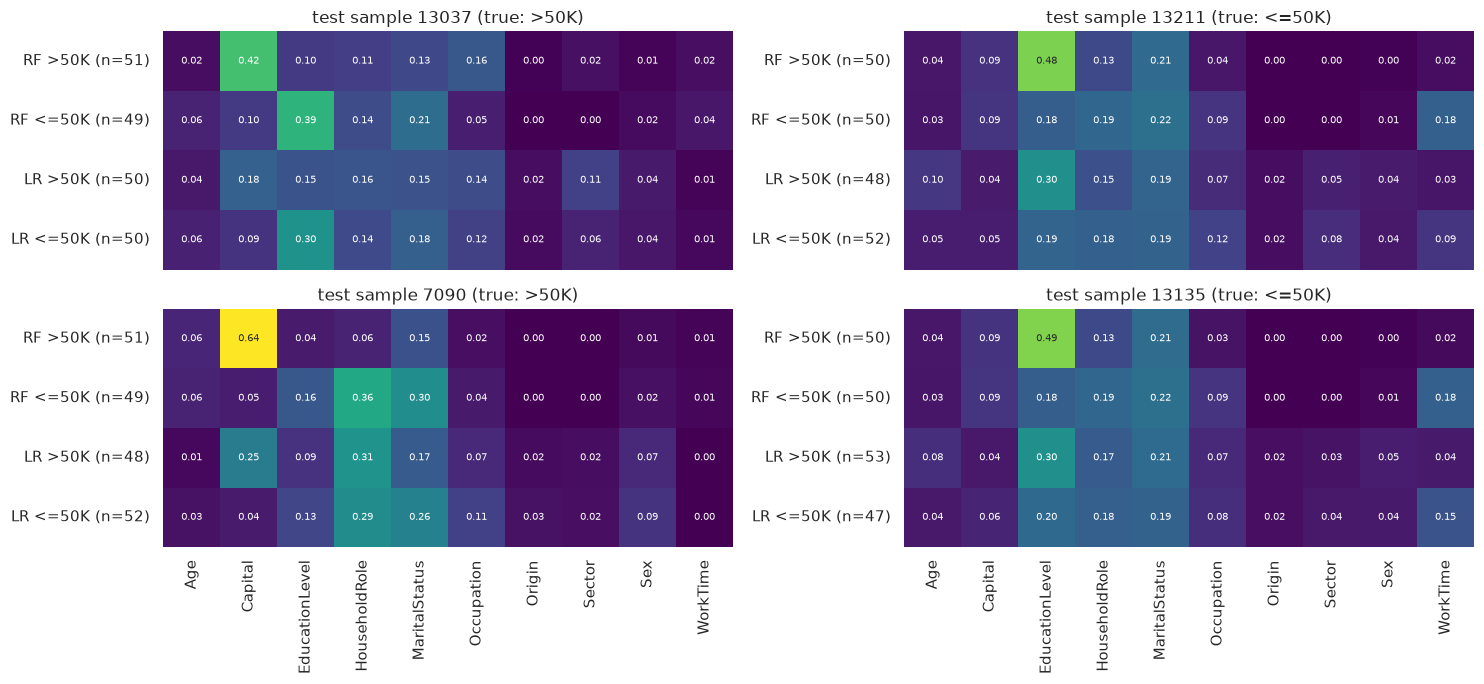

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for ax, i in zip(axes.flat, cases):
    rows, idx = [], []
    for name in models:
        vote = concepts.votes(proba[name][:, i])
        for c, lab in [(1, ">50K"), (0, "<=50K")]:
            rows.append(v[name, "leaf"][vote == c, i].mean(axis=0))
            idx.append(f"{name} {lab} (n={(vote == c).sum()})")
    sns.heatmap(pd.DataFrame(rows, index=idx, columns=names["leaf"]), ax=ax, annot=True, fmt=".2f", cmap="viridis",
                vmin=0, vmax=0.6, cbar=False, annot_kws={"fontsize": 7})
    ax.set_title(f"test sample {i} (true: {'>50K' if y_te[i] else '<=50K'})")
plt.tight_layout()
plt.gcf().savefig(FIG / "case_studies.png", dpi=200, bbox_inches="tight")

In [10]:
for i in cases:
    print(f"sample {i} (true {'>50K' if y_te[i] else '<=50K'}):")
    for name in models:
        d = pd.Series(concepts.camp_difference(v[name, "leaf"][:, [i]], proba[name][:, [i]])[0], index=names["leaf"])
        print(f"  {name}: >50K camp leans on {d.idxmax()} (+{d.max():.2f}), <=50K camp on {d.idxmin()} ({d.min():.2f})")

sample 13037 (true >50K):
  RF: >50K camp leans on Capital (+0.32), <=50K camp on EducationLevel (-0.29)
  LR: >50K camp leans on Capital (+0.10), <=50K camp on EducationLevel (-0.15)
sample 13211 (true <=50K):
  RF: >50K camp leans on EducationLevel (+0.30), <=50K camp on WorkTime (-0.16)
  LR: >50K camp leans on EducationLevel (+0.11), <=50K camp on WorkTime (-0.06)
sample 7090 (true >50K):
  RF: >50K camp leans on Capital (+0.59), <=50K camp on HouseholdRole (-0.30)
  LR: >50K camp leans on Capital (+0.20), <=50K camp on MaritalStatus (-0.09)
sample 13135 (true <=50K):
  RF: >50K camp leans on EducationLevel (+0.31), <=50K camp on WorkTime (-0.17)
  LR: >50K camp leans on EducationLevel (+0.10), <=50K camp on WorkTime (-0.11)


## Findings

- **Contested samples are rare.** 190 (RF) and 884 (LR) of 16,281 test samples have a vote margin below 0.2; 62% / 51%
  are unanimous.
- **RQ2 - prediction disagreement goes with concept disagreement, mostly on the main concept.** Over the test set, the
  vote margin correlates with top-concept entropy at -0.63 (RF, top level), -0.32 (RF, leaf), -0.39 / -0.42 (LR). For
  RF at the top level, top-concept agreement falls from 0.89 on unanimous samples to 0.51 on contested ones. The link
  with the full ranking (Kendall) is weaker (Spearman 0.08-0.20): members that vote differently still order most
  concepts alike and differ in which one dominates.
- **The `>50K` camp is the coherent one.** On contested samples, members voting `>50K` agree with each other more
  (Kendall 0.47 RF, 0.46 LR) than the ensemble as a whole (0.33 / 0.36); the `<=50K` camp is about as mixed as the
  whole ensemble (0.33 / 0.39). A `>50K` vote on a borderline sample comes from members reading the same evidence.
- **Which concepts differ.** The `>50K` camp puts more weight on `Finance` / `Capital` (+0.15 in both ensembles; in 76%
  of contested samples for RF) and, for RF, on `EducationLevel` (+0.08). The `<=50K` camp puts more weight on `Family`
  (-0.09 LR, -0.11 RF), `Demographics` and, for RF, `WorkTime` (-0.10). It also uses more `ProtectedAttribute` features
  (difference -0.06, in 87% of contested samples in both ensembles).
- **Case studies.** All four most contested samples are married, and each pits one strong cue against another, the same
  pair in both ensembles: capital loss vs. 10th-grade education (13037); a Masters degree vs. 15 or 4 hours per week
  (13211, 13135; 13135 also lacks `workclass` / `occupation`); a 5,178 capital gain vs. being a wife (7090). The camps
  differ in which cue they follow; RF camps differ more sharply (camp differences up to 0.59 vs 0.20 for LR).
  True labels are split 2 / 2, so these are genuine borderline cases.
- **Limitations.** Concept vectors are absolute, so "the `<=50K` camp relies more on `Family`" says which concept it
  weights, not that `Family` pushes it to `<=50K`. Camp sizes on contested samples are close to 50/50 by construction,
  but the `<0.2` bucket of RF holds only 190 samples. Correlations are over one test split and one seed.